In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh, plot_loss_history
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from seq_minmax_opt_class import SequentialMinMaxOptProb


import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)

In [2]:
# def u0(x):
#     u = jnp.zeros_like(x)
#     u = jnp.where((x > 0.0) & (x < 1.0), 1.0, u)
#     return u

def u0(x):
    # return 2*smooth_sign(x) - 1
    return -jnp.sign(x)

def u_exact(t, x):
    # Initialize u as zero
    u = 0.0
    # Condition 1: x < 0, u = 0 (already zero by default)
    # Condition 2: 0 < x < t and t > 0, u = x/t
    u = jnp.where((x > 0) & (x < t) & (t > 0), x / t, u)
    
    # Condition 3: t < x < 1 + t/2, u = 1
    u = jnp.where((x > t) & (x < 1 + t / 2), 1.0, u)
    
    # Condition 4: x > 1 + t/2, u = 0 (already zero by default)
    return u
vmap_u_exact = vmap(u_exact, in_axes=(0, 0), out_axes=0)

# Boundary at x=-1
def u1(x):
    return 1
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)


# Boundary at x=1
def u2(x):
    return -1
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0.0
t_max = 0.5
# num_segments = 6
x_min = -1
x_max = 1
Nt = 101
Nx = 401
layers = [2, 50, 50, 50, 50, 50, 1]
hidden_dims = layers[1:-1]

# Domain bounds
lb = jnp.array([t_min, x_min])
ub = jnp.array([t_max, x_max])

In [6]:
optProb = MinMaxOptProb(
    N_t=16,
    N_x=64,
    lr_theta=0.002,
    seed=0,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=0.5,  x_min=x_min, x_max=x_max,
    hidden_dims=hidden_dims,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.005,
    res_visc=res_visc,
    res=res,
    use_loss_elem_int=False
)


In [8]:
optProb.pwp.coeffs

Array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       ...,
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]], dtype=float32)


Plotting before training segment [0.0000, 1.0000]


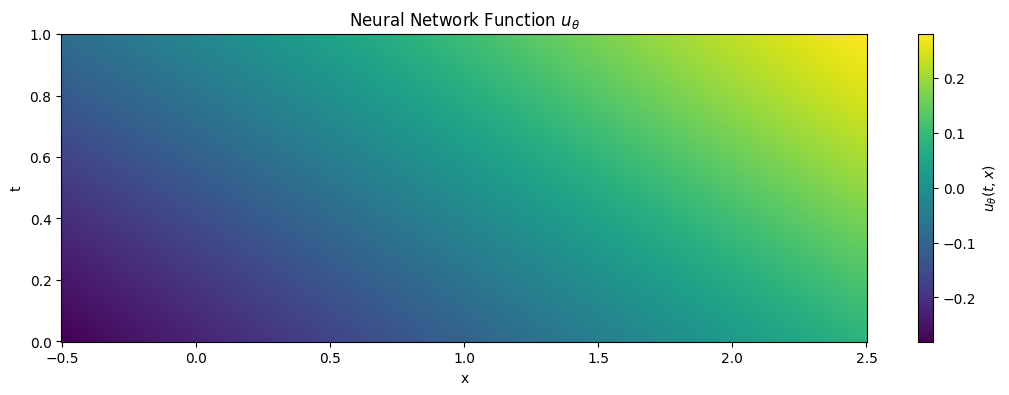


Pre-training segment [0.0000, 1.0000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 9.362467765808105, lambda_bc: 9.385849952697754, lambda_r: 1.1150792837142944.
Pre-train Iteration 0, Loss_int: 0.13040444, Loss_ibc: 0.54475141
Pre-train Iteration 200, Loss_int: 0.08360992, Loss_ibc: 0.25926414
Pre-train Iteration 400, Loss_int: 0.08981328, Loss_ibc: 0.04166510
Pre-train Iteration 600, Loss_int: 0.07490845, Loss_ibc: 0.03710641
Pre-train Iteration 800, Loss_int: 0.06066583, Loss_ibc: 0.02634704
Iteration 1000, lambda_ic: 9.123627662658691, lambda_bc: 10.686708450317383, lambda_r: 1.1267304420471191.
Pre-train Iteration 1000, Loss_int: 0.06485411, Loss_ibc: 0.01818169
Pre-train Iteration 1200, Loss_int: 0.04899858, Loss_ibc: 0.01322205
Pre-train Iteration 1400, Loss_int: 0.01930350, Loss_ibc: 0.00691068
Pre-train Iteration 1600, Loss_int: 0.00906872, Loss_ibc: 0.00490387
Pre-train Iteration 1800, Loss_int: 0.00626943, Loss_ibc: 0.00418845
Iteration 2000, lambda_ic: 9.0486307144165

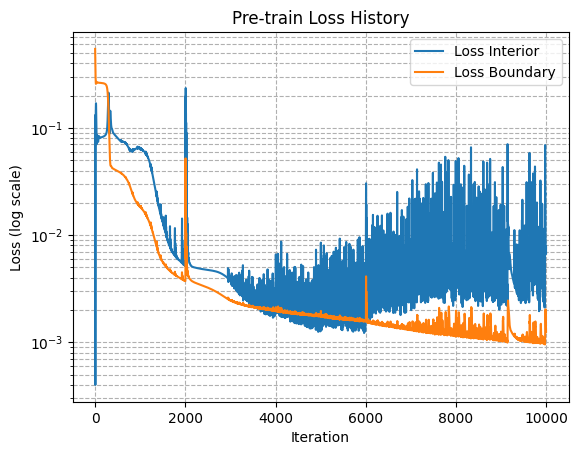


Plotting after training segment [0.0000, 1.0000]


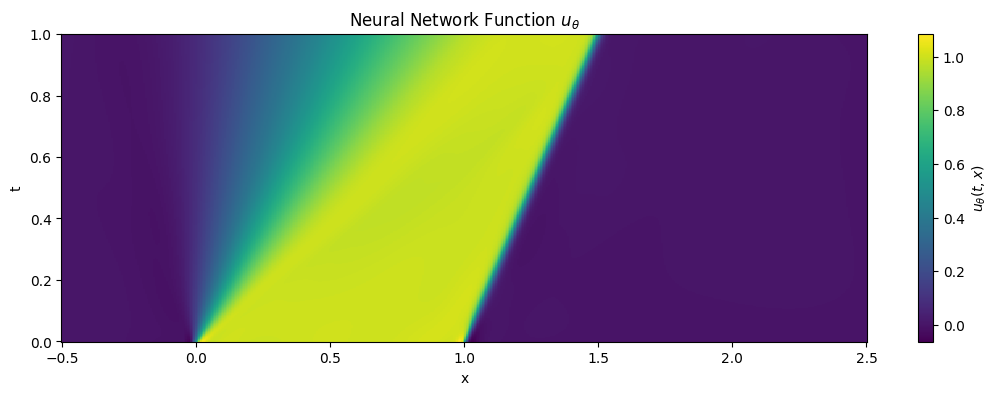


Plotting before training segment [1.0000, 2.0000]


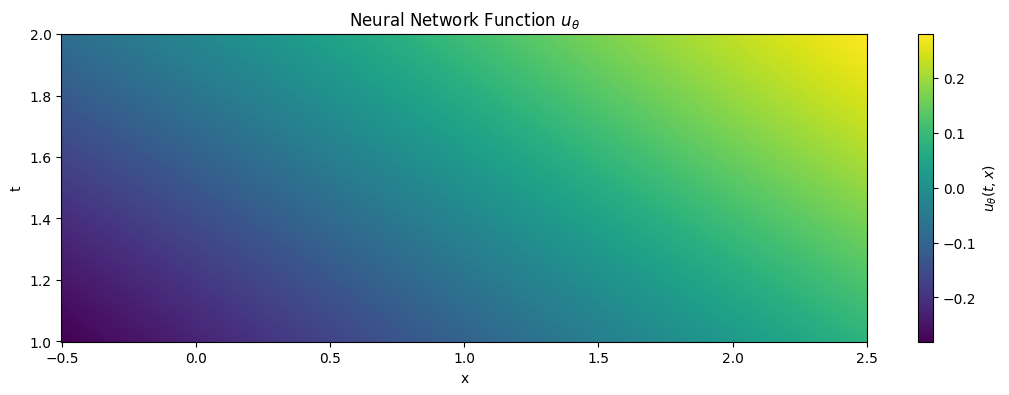


Pre-training segment [1.0000, 2.0000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 9.429433822631836, lambda_bc: 9.364211082458496, lambda_r: 1.1030173301696777.
Pre-train Iteration 0, Loss_int: 0.13040444, Loss_ibc: 0.44572595
Pre-train Iteration 200, Loss_int: 0.09047961, Loss_ibc: 0.19528601
Pre-train Iteration 400, Loss_int: 0.07197998, Loss_ibc: 0.01553372
Pre-train Iteration 600, Loss_int: 0.06873571, Loss_ibc: 0.01232388
Pre-train Iteration 800, Loss_int: 0.04784263, Loss_ibc: 0.00813648
Iteration 1000, lambda_ic: 9.171950340270996, lambda_bc: 16.723159790039062, lambda_r: 1.1114723682403564.
Pre-train Iteration 1000, Loss_int: 0.03379779, Loss_ibc: 0.00395726
Pre-train Iteration 1200, Loss_int: 0.01333276, Loss_ibc: 0.00131269
Pre-train Iteration 1400, Loss_int: 0.00653740, Loss_ibc: 0.00046386
Pre-train Iteration 1600, Loss_int: 0.00320235, Loss_ibc: 0.00028355
Pre-train Iteration 1800, Loss_int: 0.00307837, Loss_ibc: 0.00029757
Iteration 2000, lambda_ic: 8.6974115371704

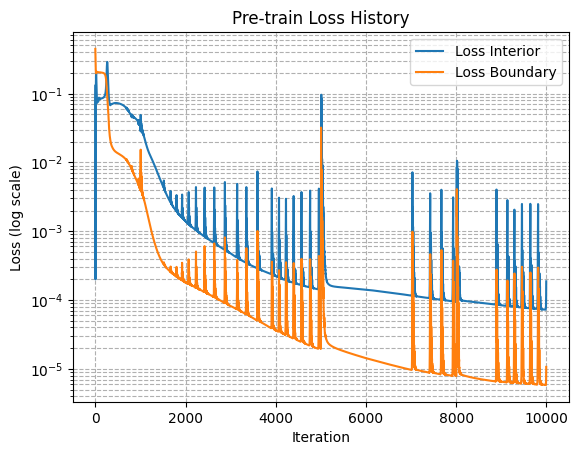


Plotting after training segment [1.0000, 2.0000]


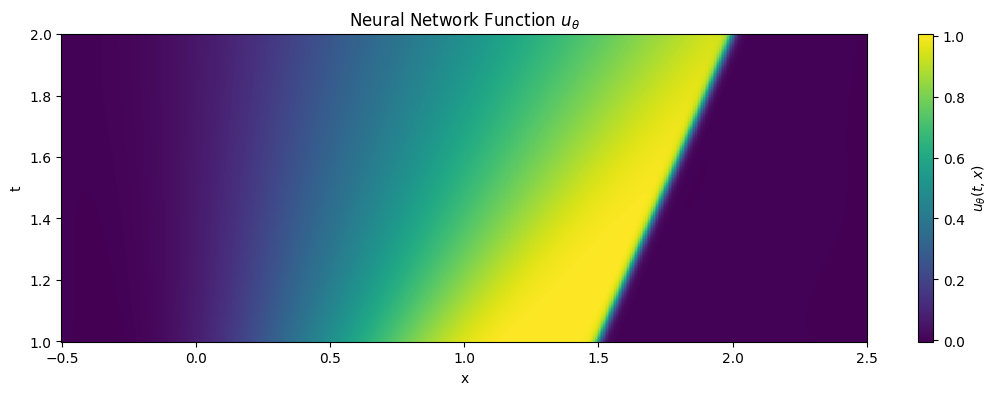


Plotting before training segment [2.0000, 2.5000]


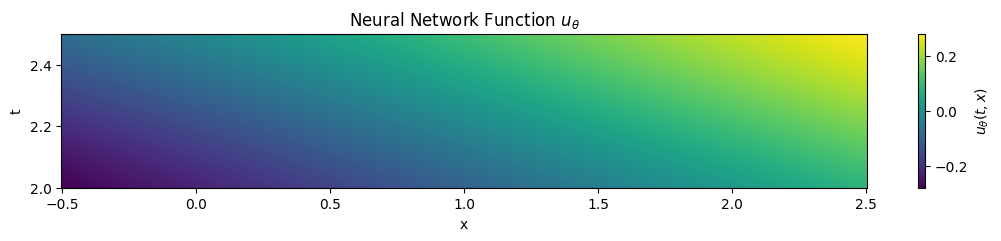


Pre-training segment [2.0000, 2.5000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 9.776267051696777, lambda_bc: 9.523777961730957, lambda_r: 1.0470030307769775.
Pre-train Iteration 0, Loss_int: 0.25980714, Loss_ibc: 0.35942596
Pre-train Iteration 200, Loss_int: 0.08388181, Loss_ibc: 0.14874673
Pre-train Iteration 400, Loss_int: 0.03386378, Loss_ibc: 0.02063811
Pre-train Iteration 600, Loss_int: 0.01889940, Loss_ibc: 0.01147224
Pre-train Iteration 800, Loss_int: 0.02556869, Loss_ibc: 0.00538943
Iteration 1000, lambda_ic: 9.461952209472656, lambda_bc: 11.185864448547363, lambda_r: 1.0656083822250366.
Pre-train Iteration 1000, Loss_int: 0.02020252, Loss_ibc: 0.00362349
Pre-train Iteration 1200, Loss_int: 0.01152641, Loss_ibc: 0.00180317
Pre-train Iteration 1400, Loss_int: 0.00307780, Loss_ibc: 0.00037756
Pre-train Iteration 1600, Loss_int: 0.00405198, Loss_ibc: 0.00066797
Pre-train Iteration 1800, Loss_int: 0.00112433, Loss_ibc: 0.00012386
Iteration 2000, lambda_ic: 8.8807487487792

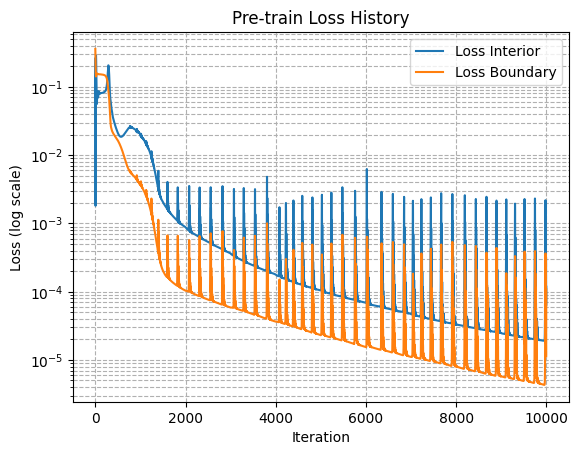


Plotting after training segment [2.0000, 2.5000]


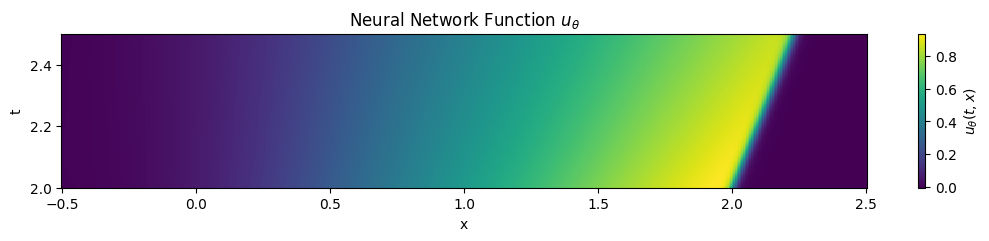


Plotting before training segment [2.5000, 3.0000]


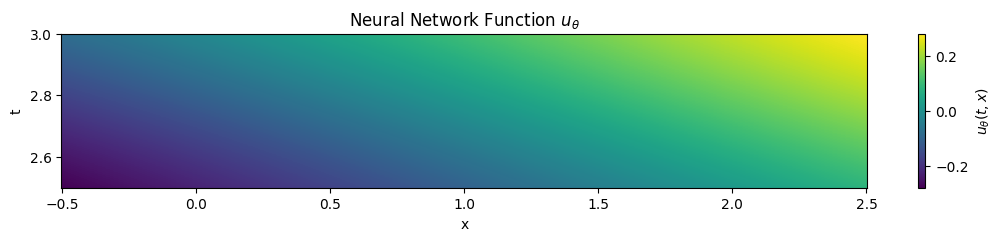


Pre-training segment [2.5000, 3.0000]

Starting Pre-Train Stage
Iteration 0, lambda_ic: 9.845373153686523, lambda_bc: 9.517522811889648, lambda_r: 1.0452473163604736.
Pre-train Iteration 0, Loss_int: 0.25980714, Loss_ibc: 0.32627174
Pre-train Iteration 200, Loss_int: 0.08362292, Loss_ibc: 0.12532844
Pre-train Iteration 400, Loss_int: 0.05225641, Loss_ibc: 0.02317227
Pre-train Iteration 600, Loss_int: 0.02293872, Loss_ibc: 0.01011951
Pre-train Iteration 800, Loss_int: 0.01543141, Loss_ibc: 0.00569575
Iteration 1000, lambda_ic: 9.653568267822266, lambda_bc: 10.48075008392334, lambda_r: 1.0624312162399292.
Pre-train Iteration 1000, Loss_int: 0.01526139, Loss_ibc: 0.00257325
Pre-train Iteration 1200, Loss_int: 0.01173552, Loss_ibc: 0.00153426
Pre-train Iteration 1400, Loss_int: 0.00580132, Loss_ibc: 0.00063276
Pre-train Iteration 1600, Loss_int: 0.00164119, Loss_ibc: 0.00018946
Pre-train Iteration 1800, Loss_int: 0.00071160, Loss_ibc: 0.00005310
Iteration 2000, lambda_ic: 9.47471237182617

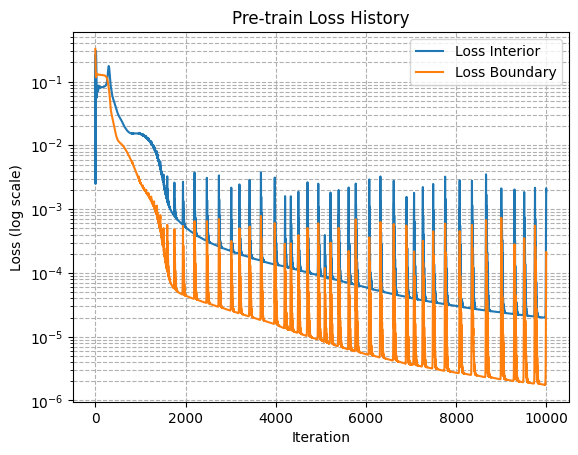


Plotting after training segment [2.5000, 3.0000]


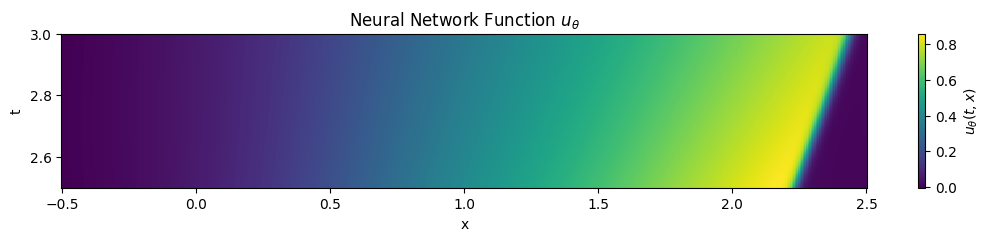


Plotting combined output across all segments from t=0 to total_t_max


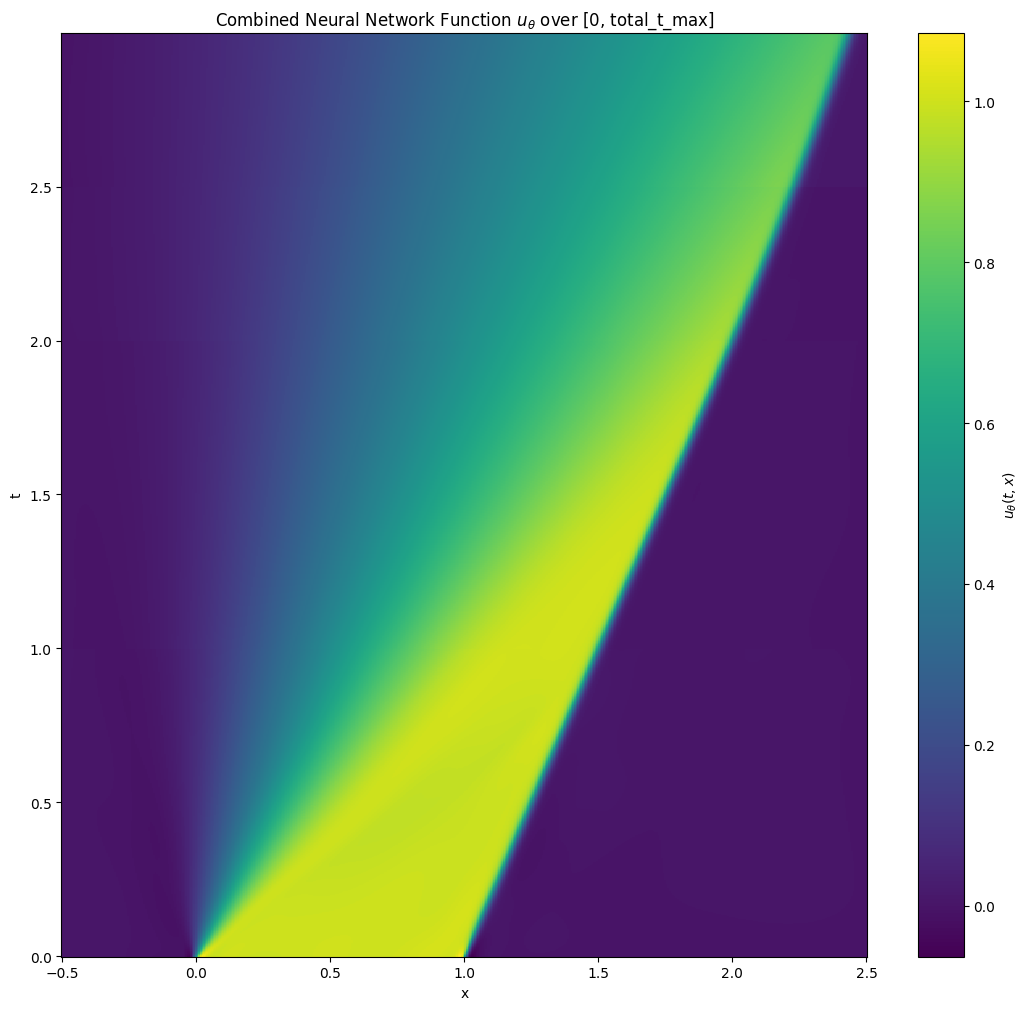

In [3]:
seq_trainer = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = [0,1,2,2.5,3.0],
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.005,
    res_visc=res_visc,
    res=res,
)
seq_trainer.train_sequential(train_num_iterations=0, pre_train_num_iterations=10000)


Plotting before training segment [0.0000, 0.5000]


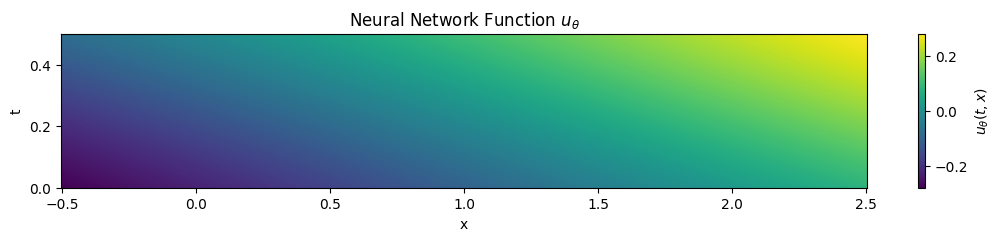


Training segment [0.0000, 0.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.59223747, lambda_bc: 9.63044167, lambda_r: 1.04869223.
Iteration 0, before maximize k_h, loss: 0.55372107, 0.54475141.
Iteration 0, after maximize k_h, loss: 0.56606859, 0.54475141.
Train Iteration 0, Loss_int: 0.56606877, Loss_bc: 0.54475141
Iteration 10, before maximize k_h, loss: 0.17953753, 0.32573238.
Iteration 10, after maximize k_h, loss: 0.14073987, 0.32573238.
Iteration 20, before maximize k_h, loss: 0.11643417, 0.31328961.
Iteration 20, after maximize k_h, loss: 0.15409397, 0.31328961.
Iteration 30, before maximize k_h, loss: 0.28078237, 0.32178059.
Iteration 30, after maximize k_h, loss: 0.30296537, 0.32178059.
Iteration 40, before maximize k_h, loss: 0.38174701, 0.33002836.
Iteration 40, after maximize k_h, loss: 0.40292799, 0.33002836.
Iteration 50, before maximize k_h, loss: 0.46951246, 0.33754686.
Iteration 50, after maximize k_h, loss: 0.46447328, 0.33754686.
Iteration 60, before maximize

KeyboardInterrupt: 

In [3]:
seq_trainer_us = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = [0, 0.5, 1, 1.5, 2, 2.5, 3.0],
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)

seq_trainer_us.train_sequential(train_num_iterations=5000, pre_train_num_iterations=0, use_loss_elem_int=True)


Plotting before training segment [0.0000, 0.5000]


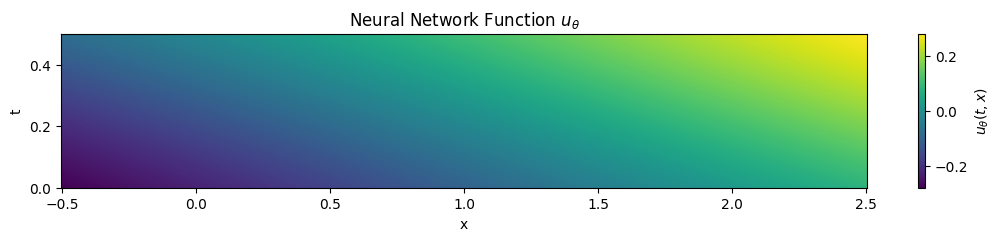


Training segment [0.0000, 0.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.61706734, lambda_bc: 9.65687370, lambda_r: 1.04583490.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.54475141.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.54475141.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.54475141
Iteration 10, before maximize k_h, loss: 0.35686234, 0.30383068.
Iteration 10, after maximize k_h, loss: 0.37610269, 0.30383068.
Iteration 20, before maximize k_h, loss: 0.28723821, 0.27512097.
Iteration 20, after maximize k_h, loss: 0.29471627, 0.27512097.
Iteration 30, before maximize k_h, loss: 0.03313305, 0.29765615.
Iteration 30, after maximize k_h, loss: 0.03320312, 0.29765615.
Iteration 40, before maximize k_h, loss: 0.07683927, 0.28787917.
Iteration 40, after maximize k_h, loss: 0.07705282, 0.28787917.
Iteration 50, before maximize k_h, loss: 0.03595031, 0.28945005.
Iteration 50, after maximize k_h, loss: 0.03646239, 0.28945005.
Iteration 60, before maximize

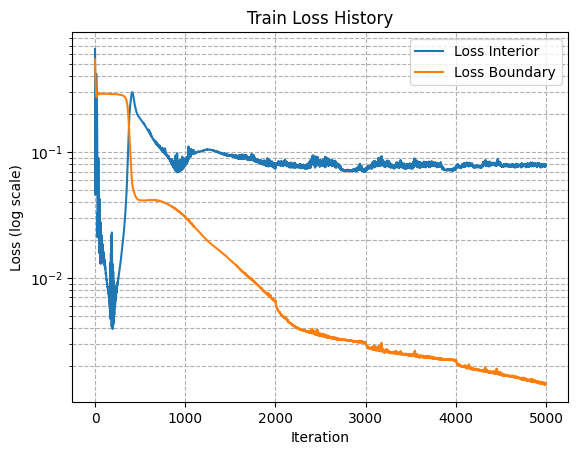


Plotting after training segment [0.0000, 0.5000]


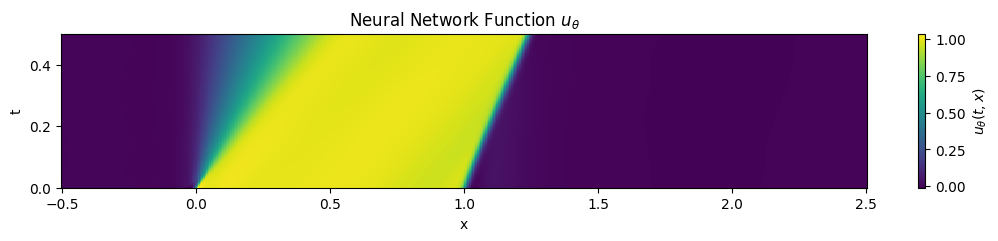


Plotting before training segment [0.5000, 1.0000]


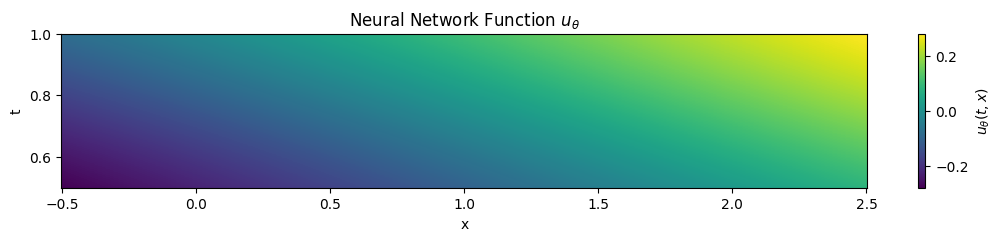


Training segment [0.5000, 1.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.68347740, lambda_bc: 9.64475727, lambda_r: 1.04314494.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.48679814.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.48679814.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.48679814
Iteration 10, before maximize k_h, loss: 0.37100095, 0.26116478.
Iteration 10, after maximize k_h, loss: 0.39384019, 0.26116478.
Iteration 20, before maximize k_h, loss: 0.29860055, 0.24118741.
Iteration 20, after maximize k_h, loss: 0.30686301, 0.24118741.
Iteration 30, before maximize k_h, loss: 0.03429548, 0.26501364.
Iteration 30, after maximize k_h, loss: 0.03450228, 0.26501364.
Iteration 40, before maximize k_h, loss: 0.08199371, 0.25392950.
Iteration 40, after maximize k_h, loss: 0.08221132, 0.25392950.
Iteration 50, before maximize k_h, loss: 0.03163425, 0.25633150.
Iteration 50, after maximize k_h, loss: 0.03272543, 0.25633150.
Iteration 60, before maximize

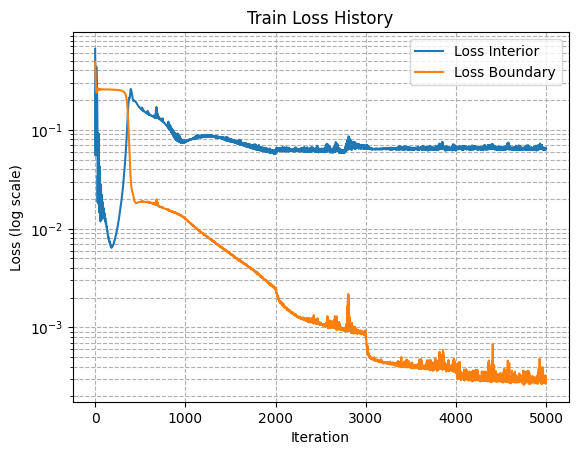


Plotting after training segment [0.5000, 1.0000]


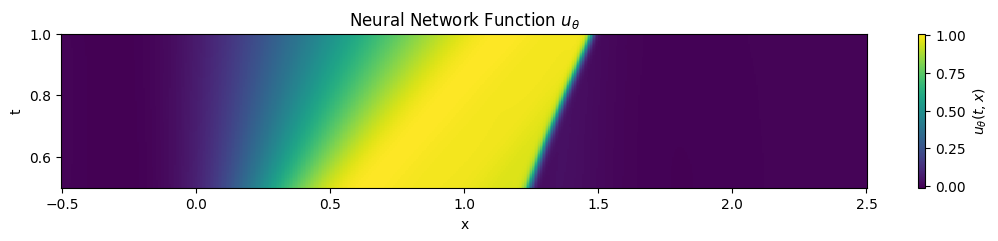


Plotting before training segment [1.0000, 1.5000]


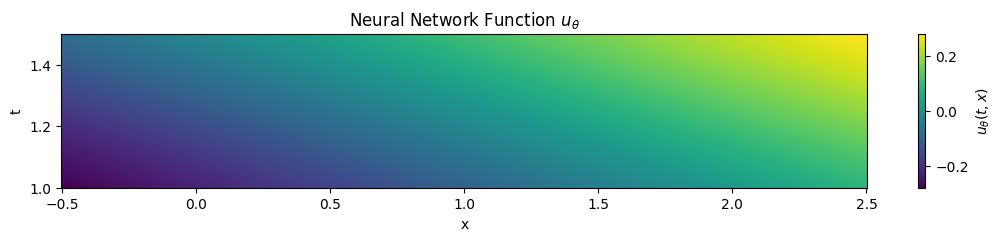


Training segment [1.0000, 1.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.75932217, lambda_bc: 9.63390541, lambda_r: 1.04073572.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.43724042.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.43724042.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.43724042
Iteration 10, before maximize k_h, loss: 0.39452213, 0.22481307.
Iteration 10, after maximize k_h, loss: 0.41041970, 0.22481307.
Iteration 20, before maximize k_h, loss: 0.31623727, 0.21147659.
Iteration 20, after maximize k_h, loss: 0.32071927, 0.21147659.
Iteration 30, before maximize k_h, loss: 0.03381192, 0.23573081.
Iteration 30, after maximize k_h, loss: 0.03459750, 0.23573081.
Iteration 40, before maximize k_h, loss: 0.09032798, 0.22363581.
Iteration 40, after maximize k_h, loss: 0.09040549, 0.22363581.
Iteration 50, before maximize k_h, loss: 0.02464717, 0.22723302.
Iteration 50, after maximize k_h, loss: 0.02691888, 0.22723302.
Iteration 60, before maximize

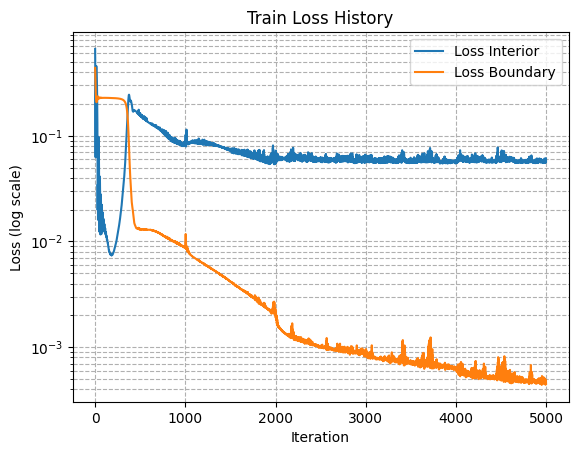


Plotting after training segment [1.0000, 1.5000]


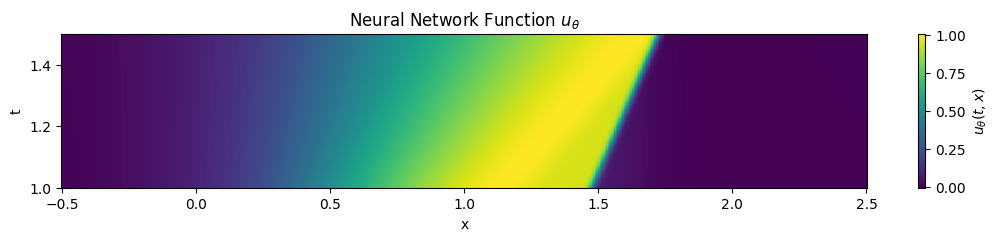


Plotting before training segment [1.5000, 2.0000]


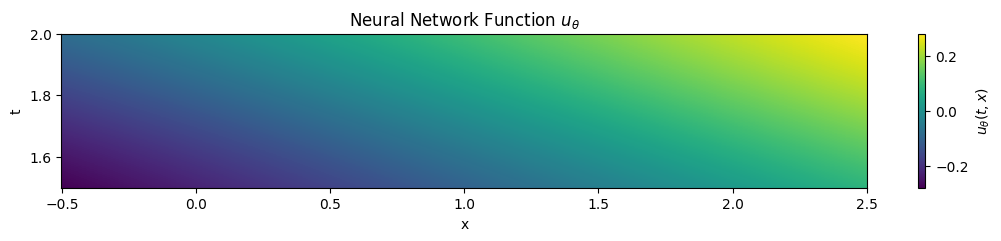


Training segment [1.5000, 2.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.82329464, lambda_bc: 9.62652206, lambda_r: 1.03909647.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.39885771.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.39885771.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.39885774
Iteration 10, before maximize k_h, loss: 0.41697031, 0.19303618.
Iteration 10, after maximize k_h, loss: 0.43286899, 0.19303618.
Iteration 20, before maximize k_h, loss: 0.35019064, 0.18270801.
Iteration 20, after maximize k_h, loss: 0.35484383, 0.18270801.
Iteration 30, before maximize k_h, loss: 0.00035301, 0.20782565.
Iteration 30, after maximize k_h, loss: 0.02364915, 0.20782565.
Iteration 40, before maximize k_h, loss: 0.09289944, 0.19595969.
Iteration 40, after maximize k_h, loss: 0.09305665, 0.19595969.
Iteration 50, before maximize k_h, loss: 0.01127421, 0.20096438.
Iteration 50, after maximize k_h, loss: 0.01646585, 0.20096438.
Iteration 60, before maximize

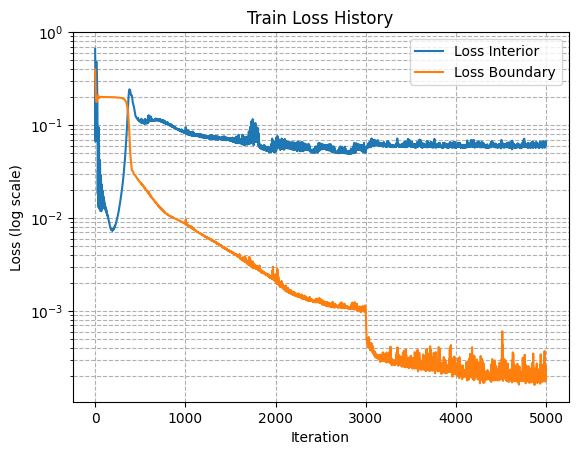


Plotting after training segment [1.5000, 2.0000]


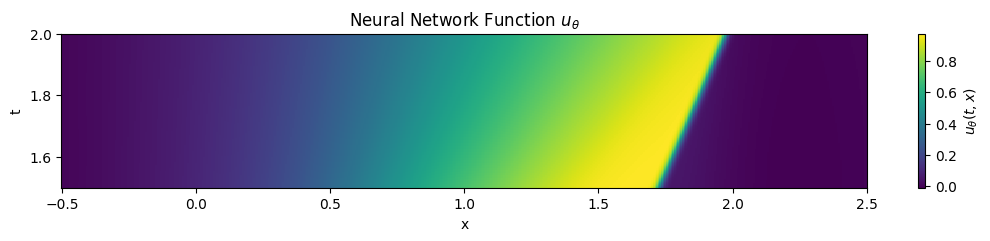


Plotting before training segment [2.0000, 2.5000]


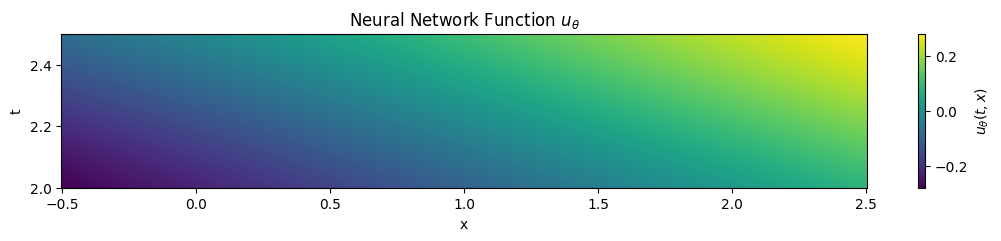


Training segment [2.0000, 2.5000]

Starting Train Stage
Iteration 0, lambda_ic: 9.90134621, lambda_bc: 9.61911011, lambda_r: 1.03745091.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.35991016.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.35991016.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.35991016
Iteration 10, before maximize k_h, loss: 0.44448039, 0.16124308.
Iteration 10, after maximize k_h, loss: 0.45352545, 0.16124308.
Iteration 20, before maximize k_h, loss: 0.37899584, 0.15361845.
Iteration 20, after maximize k_h, loss: 0.38285938, 0.15361845.
Iteration 30, before maximize k_h, loss: 0.00482139, 0.17782281.
Iteration 30, after maximize k_h, loss: 0.01326094, 0.17782281.
Iteration 40, before maximize k_h, loss: 0.08959497, 0.16794005.
Iteration 40, after maximize k_h, loss: 0.08975287, 0.16794005.
Iteration 50, before maximize k_h, loss: 0.01028410, 0.17353341.
Iteration 50, after maximize k_h, loss: 0.01324316, 0.17353341.
Iteration 60, before maximize

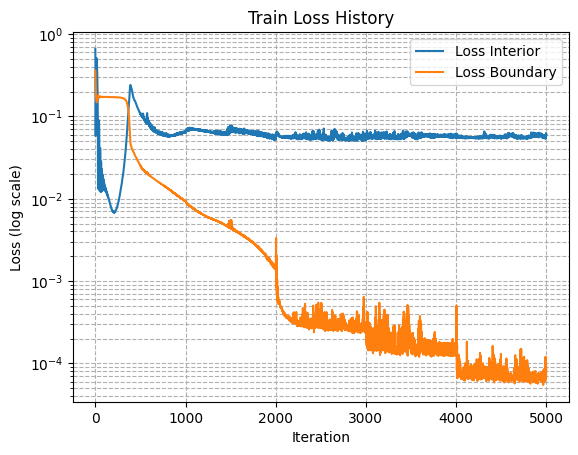


Plotting after training segment [2.0000, 2.5000]


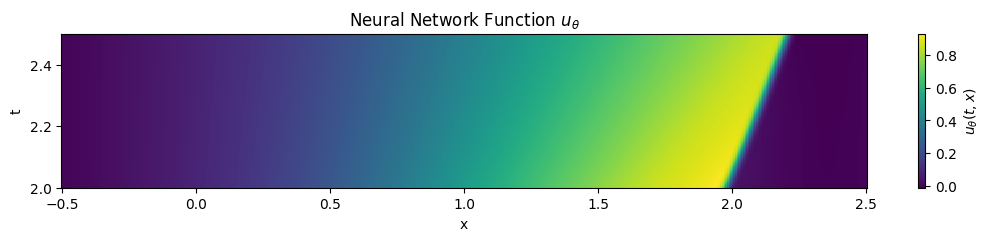


Plotting before training segment [2.5000, 3.0000]


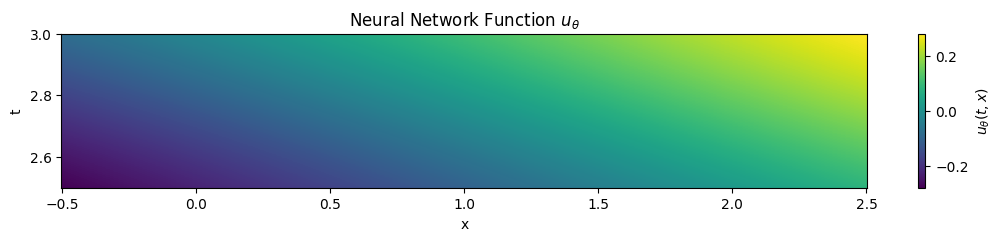


Training segment [2.5000, 3.0000]

Starting Train Stage
Iteration 0, lambda_ic: 9.99279118, lambda_bc: 9.61207390, lambda_r: 1.03588891.
Iteration 0, before maximize k_h, loss: 0.66072565, 0.32377720.
Iteration 0, after maximize k_h, loss: 0.66072565, 0.32377720.
Train Iteration 0, Loss_int: 0.66072571, Loss_bc: 0.32377723
Iteration 10, before maximize k_h, loss: 0.45945832, 0.13353796.
Iteration 10, after maximize k_h, loss: 0.46537536, 0.13353796.
Iteration 20, before maximize k_h, loss: 0.39116552, 0.12869656.
Iteration 20, after maximize k_h, loss: 0.39350072, 0.12869656.
Iteration 30, before maximize k_h, loss: 0.00973775, 0.15187976.
Iteration 30, after maximize k_h, loss: 0.01454454, 0.15187976.
Iteration 40, before maximize k_h, loss: 0.08836644, 0.14293088.
Iteration 40, after maximize k_h, loss: 0.08846641, 0.14293088.
Iteration 50, before maximize k_h, loss: 0.01035912, 0.14845453.
Iteration 50, after maximize k_h, loss: 0.01400691, 0.14845453.
Iteration 60, before maximize

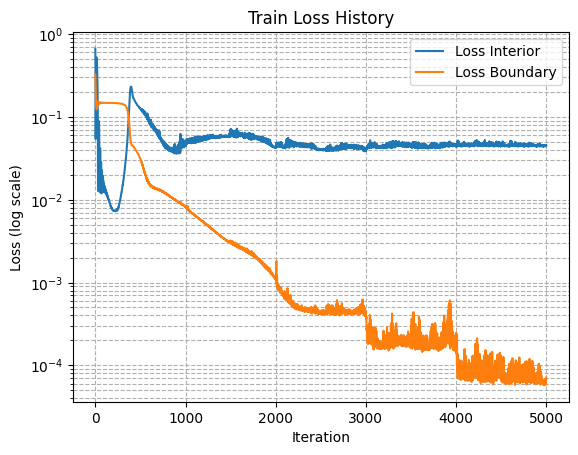


Plotting after training segment [2.5000, 3.0000]


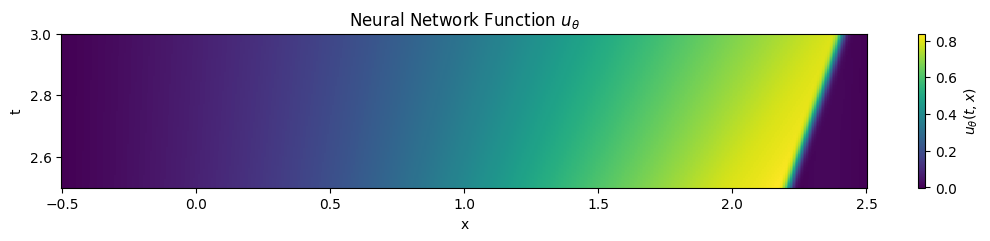


Plotting combined output across all segments from t=0 to total_t_max


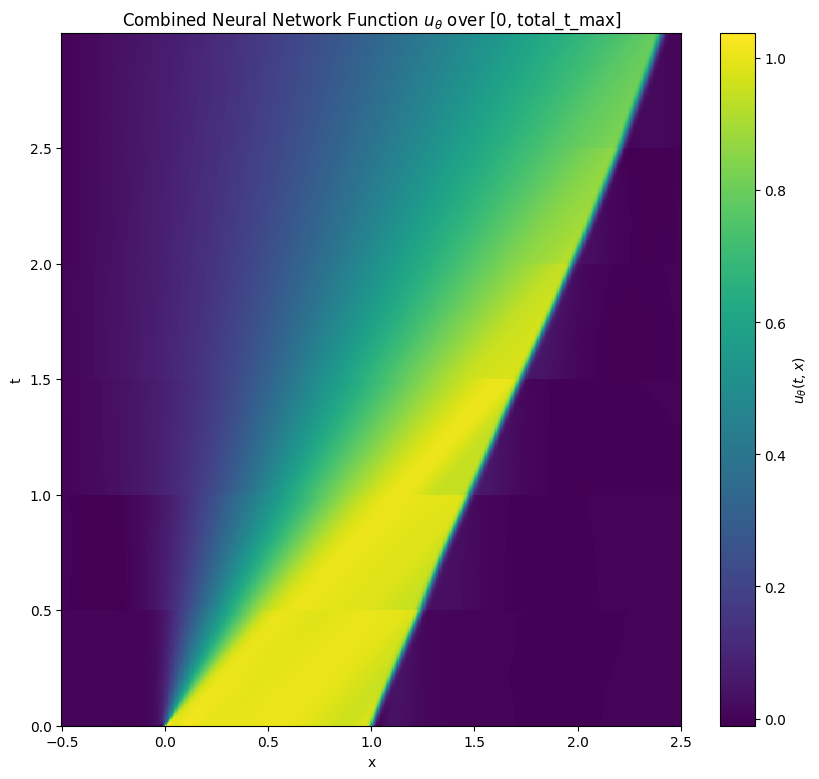

In [3]:
seq_trainer_us = SequentialMinMaxOptProb(
    num_segments=num_segments,
    total_t_min=t_min,
    total_t_max=t_max,
    seq_T = [0, 0.5, 1, 1.5, 2, 2.5, 3.0],
    N_t=16,
    N_x=48,
    lr_theta=0.0002,
    hidden_dims=hidden_dims,
    seed=0,
    N_bc=Nt,
    N_ic=Nx,
    x_min=x_min, x_max=x_max,
    u0=u0, u1=vmap_u1, u2=vmap_u2,
    nu=0.01,
    res_visc=res_visc,
    res=res, 
    use_loss_elem_int=True,
)

seq_trainer_us.train_sequential(train_num_iterations=5000, pre_train_num_iterations=0)

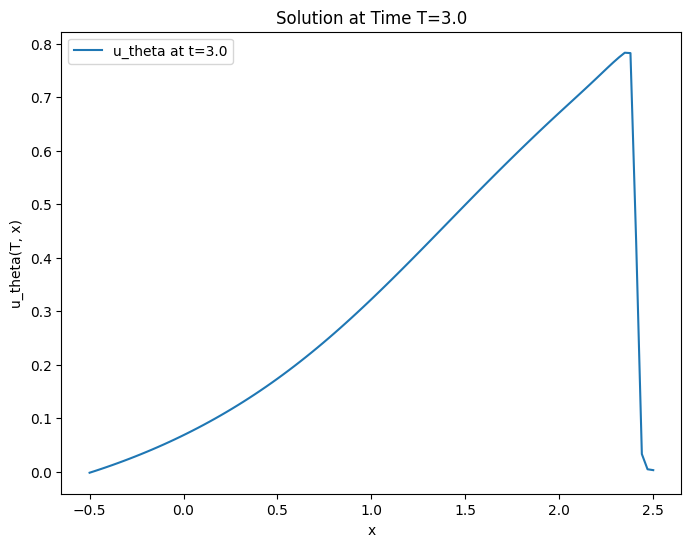

In [4]:
seq_trainer_us.plot_solution_at_time(seq_trainer_us.total_t_max)